# Türkiye'nin elektriğinde yenilenebilir enerji (2000–2025)
**Veri Hikâyesi Proje Ödevi · Analiz notebook'u**
Ayşe Dudu Tursun · Öğrenci no: 2516016019

**Çalışma sorusu:** Türkiye'nin elektrik üretiminde yenilenebilir enerjinin payı 2000'den bu yana belirgin biçimde arttı. Bu artışı hidroelektrik mi, yoksa rüzgâr ve güneş mi sağladı? Türkiye bu yolda diğer ülkelerin neresinde duruyor?

**Veri:** Our World in Data – Energy Dataset (`owid-energy-data.csv`). Kaynaklar: Ember, Energy Institute (Statistical Review of World Energy), EIA. Lisans: CC BY 4.0. Bağlantı: https://github.com/owid/energy-data · Erişim tarihi: 17 Ekim 2026.

**Akış:** 1) Veri yükleme → 2) Temizleme → 3) Keşifsel analiz → 4) Bulgular → 5) Sitede kullanılan özet dosyaların üretimi ve dışa aktarımı.

## 0. Kurulum
Notebook hem `notebooks/` klasöründen hem de depo kökünden çalıştırılabilir. Gerekli paketler `requirements.txt` içinde listelidir.

In [1]:
from pathlib import Path
import json, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pycountry
from babel import Locale

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw" / "owid-energy-data.csv"
OUT = ROOT / "data" / "processed"
SITE_DATA = ROOT / "site" / "data"
OUT.mkdir(parents=True, exist_ok=True)
SITE_DATA.mkdir(parents=True, exist_ok=True)
RAW_URL = "https://raw.githubusercontent.com/owid/energy-data/master/owid-energy-data.csv"

def tr(x, d=1):
    # Türkçe sayı yazımı: ondalık virgül, binlik nokta
    s = f"{x:,.{d}f}"
    return s.replace(",", "X").replace(".", ",").replace("X", ".")

print("Depo kökü:", ROOT)

Depo kökü: /home/claude/repo/turkiye-yenilenebilir-elektrik


## 1. Veri yükleme
Ham verinin 17 Ekim 2026'da indirilmiş bir kopyası `data/raw/` klasöründedir. OWID dosyayı düzenli olarak güncellediği için analiz bu sabit kopya üzerinden yapılır; dosya yoksa güncel sürüm indirilir.

In [2]:
if not RAW.exists():
    RAW.parent.mkdir(parents=True, exist_ok=True)
    pd.read_csv(RAW_URL).to_csv(RAW, index=False)
raw = pd.read_csv(RAW)
print(f"{raw.shape[0]:,} satır × {raw.shape[1]} sütun; yıllar {raw.year.min()}–{raw.year.max()}")
raw.head(3)

23,377 satır × 130 sütun; yıllar 1900–2025


,country,year,iso_code,population,gdp,biofuel_cons_change_pct,biofuel_cons_change_twh,biofuel_cons_per_capita,biofuel_consumption,biofuel_elec_per_capita,biofuel_electricity,biofuel_share_elec,biofuel_share_energy,carbon_intensity_elec,coal_cons_change_pct,...,solar_cons_change_twh,solar_consumption,solar_elec_per_capita,solar_electricity,solar_energy_per_capita,solar_share_elec,solar_share_energy,wind_cons_change_pct,wind_cons_change_twh,wind_consumption,wind_elec_per_capita,wind_electricity,wind_energy_per_capita,wind_share_elec,wind_share_energy
0,ASEAN (Ember),2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.87,1.550,NaN,572.58,NaN,...,NaN,NaN,NaN,0.0,NaN,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN
1,ASEAN (Ember),2001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.46,1.595,NaN,570.27,NaN,...,NaN,NaN,NaN,0.0,NaN,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN
2,ASEAN (Ember),2002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.62,1.528,NaN,572.68,NaN,...,NaN,NaN,NaN,0.0,NaN,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN


Projede kullanılan değişkenler (hepsi elektrik üretimiyle ilgili):

| Değişken | Anlamı | Birim |
|---|---|---|
| `country`, `iso_code`, `year` | Ülke/bölge, ISO-3 kodu, yıl | – |
| `electricity_generation` | Toplam elektrik üretimi | TWh |
| `renewables_share_elec` | Yenilenebilir kaynakların üretimdeki payı | % |
| `hydro_share_elec`, `wind_share_elec`, `solar_share_elec` | Hidroelektrik, rüzgâr, güneş payı | % |
| `other_renewables_share_elec` | Diğer yenilenebilir (jeotermal, biyoenerji vb.) payı | % |
| `fossil_share_elec` | Fosil yakıt (kömür, gaz, petrol) payı | % |
| `*_electricity` | Kaynak bazında üretim | TWh |

**TWh (teravatsaat):** 1 milyar kilovatsaat. Bir hanenin yıllık tüketimi birkaç bin kWh olduğundan 1 TWh kabaca birkaç yüz bin hanenin bir yıllık tüketimine denk gelir.

In [3]:
COLS = ["country", "iso_code", "year", "population", "electricity_generation",
        "renewables_share_elec", "hydro_share_elec", "wind_share_elec", "solar_share_elec",
        "other_renewables_share_elec", "fossil_share_elec", "nuclear_share_elec",
        "renewables_electricity", "hydro_electricity", "wind_electricity", "solar_electricity",
        "other_renewable_electricity", "fossil_electricity", "carbon_intensity_elec",
        "per_capita_electricity"]
df = raw[COLS].copy()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 23377 entries, 0 to 23376
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   country                      23377 non-null  str    
 1   iso_code                     17265 non-null  str    
 2   year                         23377 non-null  int64  
 3   population                   18894 non-null  float64
 4   electricity_generation       7913 non-null   float64
 5   renewables_share_elec        7872 non-null   float64
 6   hydro_share_elec             7777 non-null   float64
 7   wind_share_elec              7661 non-null   float64
 8   solar_share_elec             7869 non-null   float64
 9   other_renewables_share_elec  7844 non-null   float64
 10  fossil_share_elec            7182 non-null   float64
 11  nuclear_share_elec           7718 non-null   float64
 12  renewables_electricity       9698 non-null   float64
 13  hydro_electricity          

## 2. Temizleme
### 2.1 Ülkeler ve bölge toplamları
Veri setinde ülkelerin yanında "World", "Europe", "G20 (Ember)" gibi toplamlar da var. Toplamların `iso_code` değeri boştur ya da `OWID_` ile başlar. Sıralamalarda yalnızca ülkeler kullanılır; birkaç toplam (Dünya, AB-27, Avrupa, G20, OECD) karşılaştırma çizgisi olarak ayrıca tutulur.

In [4]:
is_country = df.iso_code.notna() & ~df.iso_code.astype(str).str.startswith("OWID")
countries = df[is_country].copy()
AGG = {"World": "Dünya", "European Union (27)": "Avrupa Birliği (27)", "Europe": "Avrupa",
       "G20 (Ember)": "G20", "OECD (Ember)": "OECD"}
aggs = df[df.country.isin(AGG)].copy()
print("Ülke sayısı:", countries.country.nunique(), "| Seçilen toplamlar:", aggs.country.nunique())

Ülke sayısı: 220 | Seçilen toplamlar: 5


### 2.2 Türkçe ülke adları
Site Türkçe olduğu için ülke adları ISO kodundan Türkçeye çevrilir (`pycountry` ile ISO-3 → ISO-2, `babel` ile Türkçe ad). Çeviri bulunamayan ülke olursa İngilizce ad korunur ve listelenir.

In [5]:
tr_loc = Locale("tr")
def turkce_ad(iso3, en):
    try:
        a2 = pycountry.countries.get(alpha_3=iso3).alpha_2
        return tr_loc.territories.get(a2, en)
    except Exception:
        return en
names = {r.country: turkce_ad(r.iso_code, r.country) for r in countries[["country", "iso_code"]].drop_duplicates().itertuples()}
names.update(AGG)
KISA = {"United States": "ABD", "European Union (27)": "AB-27", "United Kingdom": "Birleşik Krallık"}
cevrilemeyen = [k for k, v in names.items() if k == v and k not in AGG]
print("Türkiye →", names["Turkey"])
print("Adı İngilizceyle aynı kalanlar (çoğu Türkçede de aynı yazılır, ör. Pakistan, Peru):", len(cevrilemeyen))

Türkiye → Türkiye
Adı İngilizceyle aynı kalanlar (çoğu Türkçede de aynı yazılır, ör. Pakistan, Peru): 55


### 2.3 Dönem seçimi ve eksik değerler
Analiz 2000–2025 dönemini kapsar. Türkiye için kullanılan sütunlarda eksik değer olup olmadığı kontrol edilir.

In [6]:
Y0, Y1 = 2000, int(df.year.max())
tur = countries[(countries.country == "Turkey") & countries.year.between(Y0, Y1)].set_index("year")
kontrol = ["electricity_generation", "renewables_share_elec", "hydro_share_elec", "wind_share_elec",
           "solar_share_elec", "other_renewables_share_elec", "fossil_share_elec",
           "hydro_electricity", "wind_electricity", "solar_electricity", "other_renewable_electricity"]
print("Türkiye satır sayısı:", len(tur), f"({Y0}–{Y1})")
print("Eksik değer sayısı:\n", tur[kontrol].isna().sum().to_string())

Türkiye satır sayısı: 26 (2000–2025)
Eksik değer sayısı:
 electricity_generation         0
renewables_share_elec          0
hydro_share_elec               0
wind_share_elec                0
solar_share_elec               0
other_renewables_share_elec    0
fossil_share_elec              0
hydro_electricity              0
wind_electricity               0
solar_electricity              0
other_renewable_electricity    0


Türkiye serisinde eksik değer yok. 2000 yılında güneş için 0 değeri vardır; bu bir eksiklik değil, o yıl şebekeye bağlı güneş üretiminin kayda değer olmadığını gösterir.

### 2.4 Tutarlılık kontrolü
Yenilenebilir payı, alt kaynakların toplamına eşit olmalı: `renewables = hydro + wind + solar + other`. Fark 0,1 puandan büyükse işaretlenir.

In [7]:
def tutarlilik(d):
    parca = d[["hydro_share_elec", "wind_share_elec", "solar_share_elec", "other_renewables_share_elec"]].sum(axis=1, min_count=4)
    return (d["renewables_share_elec"] - parca).abs()

fark_tur = tutarlilik(tur)
print("Türkiye en büyük fark (puan):", round(fark_tur.max(), 4))
c = countries[countries.year.between(Y0, Y1)]
fark_all = tutarlilik(c)
print("Tüm ülkelerde 0,1 puandan büyük fark olan satır:", int((fark_all > 0.1).sum()), "/", int(fark_all.notna().sum()))

Türkiye en büyük fark (puan): 0.001
Tüm ülkelerde 0,1 puandan büyük fark olan satır: 0 / 5080


### 2.5 Aykırı değerler: hidroelektrikteki sert düşüşler hata mı?
Türkiye'nin hidroelektrik üretimi bazı yıllarda %20–40 düşüyor. Bunlar veri hatası değil: barajlardan üretilen elektrik o yılın yağışına ve rezerv seviyelerine bağlıdır. Bu yüzden değerler **çıkarılmadı**. Bunun yerine tek bir yılın kuraklığının sonucu çarpıtmaması için başlangıç ve bitiş karşılaştırmalarında **üç yıllık ortalama** kullanıldı (2000–2002 ve 2023–2025).

In [8]:
h = tur["hydro_electricity"]
yoy = (h.pct_change() * 100).round(1)
print("Hidroelektrikte yıllık değişim (%), en sert 5 düşüş:")
print(yoy.nsmallest(5).to_string())

Hidroelektrikte yıllık değişim (%), en sert 5 düşüş:
year
2014   -31.6
2021   -28.7
2025   -23.2
2001   -22.2
2007   -19.0


### 2.6 Küçük elektrik sistemleri ve 2025 kapsamı
- Çok küçük elektrik sistemlerinde (ör. birkaç ada ülkesi) tek bir santral payı %0'dan %100'e taşıyabilir. Bu yüzden **ülke sıralamaları ve dağılım grafiği yalnızca yıllık üretimi en az 10 TWh olan ülkelerle** yapıldı. Keşif grafiğinde arama listesinde en az 1 TWh üreten ülkeler yer alır.
- 2025 verisi henüz tüm ülkeler için yayımlanmadı. Bu nedenle **Türkiye'nin kendi hikâyesi 2025'e kadar**, **ülke karşılaştırmaları 2024 yılıyla** yapıldı.

In [9]:
for y in (2023, 2024, 2025):
    n = countries[(countries.year == y) & (countries.electricity_generation >= 10)].renewables_share_elec.notna().sum()
    print(f"{y}: ≥10 TWh üreten ve yenilenebilir payı olan ülke sayısı = {n}")
CMP_YEAR = 2024

2023: ≥10 TWh üreten ve yenilenebilir payı olan ülke sayısı = 108
2024: ≥10 TWh üreten ve yenilenebilir payı olan ülke sayısı = 108
2025: ≥10 TWh üreten ve yenilenebilir payı olan ülke sayısı = 78


## 3. Keşifsel analiz
### 3.1 Türkiye'nin elektrik üretimi ve kaynak karışımı

In [10]:
tur_t = tur[["electricity_generation", "renewables_share_elec", "hydro_share_elec", "wind_share_elec",
             "solar_share_elec", "other_renewables_share_elec", "fossil_share_elec"]].round(1)
tur_t.loc[[2000, 2005, 2010, 2015, 2020, 2023, 2024, 2025]]

,electricity_generation,renewables_share_elec,hydro_share_elec,wind_share_elec,solar_share_elec,other_renewables_share_elec,fossil_share_elec
year,,,,,,,
2000,124.4,25.1,24.8,0.0,0.0,0.2,74.9
2005,161.6,24.6,24.5,0.0,0.0,0.1,75.4
2010,211.2,26.4,24.5,1.4,0.0,0.5,73.6
2015,261.8,32.0,25.7,4.4,0.1,1.8,68.0
2020,302.0,42.2,25.8,8.1,3.7,4.5,57.8
2023,319.8,42.0,19.9,10.6,5.8,5.7,58.0
2024,341.2,45.6,21.9,10.7,7.5,5.5,54.4
2025,353.9,43.3,16.2,11.1,10.5,5.4,56.7


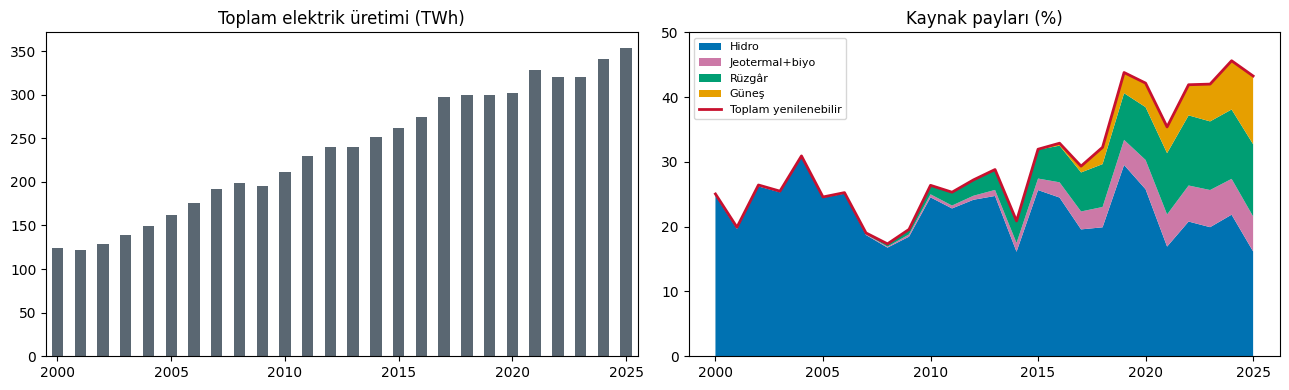

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
tur["electricity_generation"].plot.bar(ax=ax[0], color="#5A6772")
ax[0].set_title("Toplam elektrik üretimi (TWh)"); ax[0].set_xlabel("")
ax[0].set_xticks(range(0, len(tur), 5)); ax[0].set_xticklabels(tur.index[::5], rotation=0)
cols = {"hydro_share_elec": "#0072B2", "other_renewables_share_elec": "#CC79A7",
        "wind_share_elec": "#009E73", "solar_share_elec": "#E69F00"}
ax[1].stackplot(tur.index, *[tur[c] for c in cols], colors=list(cols.values()),
                labels=["Hidro", "Jeotermal+biyo", "Rüzgâr", "Güneş"])
ax[1].plot(tur.index, tur["renewables_share_elec"], color="#C8102E", lw=2, label="Toplam yenilenebilir")
ax[1].set_ylim(0, 50); ax[1].set_title("Kaynak payları (%)"); ax[1].legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

**Gözlemler:** (1) Üretim 2000'den 2025'e yaklaşık üç katına çıkmış. (2) Yenilenebilir toplamı yıldan yıla zikzak çiziyor; zikzakları hemen tamamen hidroelektrik belirliyor. (3) Rüzgâr 2008 sonrası, güneş 2016 sonrası hızla büyüyor.

### 3.2 Hareketli ortalama
**Hareketli ortalama**, her yılın değerini kendisi ve önceki iki yılın ortalamasıyla değiştirerek kısa vadeli inişleri çıkışları yumuşatır. Burada 3 yıllık geriye dönük ortalama kullanıldı.

In [12]:
tur["renew_ma3"] = tur["renewables_share_elec"].rolling(3).mean()
tur[["renewables_share_elec", "renew_ma3"]].round(1).tail(8)

,renewables_share_elec,renew_ma3
year,,
2018,32.3,31.5
2019,43.8,35.1
2020,42.2,39.4
2021,35.4,40.5
2022,41.9,39.8
2023,42.0,39.8
2024,45.6,43.2
2025,43.3,43.6


### 3.3 Ülkeler arasında Türkiye (2024)

In [13]:
big = countries[(countries.year == CMP_YEAR) & (countries.electricity_generation >= 10)].dropna(subset=["renewables_share_elec"]).copy()
big["ws"] = big.wind_share_elec + big.solar_share_elec
big["sira_ren"] = big.renewables_share_elec.rank(ascending=False, method="min")
big["sira_ws"] = big.ws.rank(ascending=False, method="min")
t = big[big.country == "Turkey"].iloc[0]
print(f"≥10 TWh üreten {len(big)} ülke içinde Türkiye: yenilenebilir payında {int(t.sira_ren)}., rüzgâr+güneş payında {int(t.sira_ws)}.")
big.sort_values("renewables_share_elec", ascending=False)[["country", "renewables_share_elec", "ws"]].head(10).round(1)

≥10 TWh üreten 108 ülke içinde Türkiye: yenilenebilir payında 49., rüzgâr+güneş payında 25.


,country,renewables_share_elec,ws
2707,Bhutan,100.0,0.0
9573,Iceland,100.0,0.1
6830,Ethiopia,100.0,2.9
5679,Democratic Republic of Congo,100.0,15.8
13606,Nepal,100.0,1.2
17080,Paraguay,100.0,0.0
4992,Costa Rica,99.9,12.1
22286,Uruguay,98.9,42.8
15169,Norway,98.6,9.6
20432,Tajikistan,94.6,0.0


In [14]:
G20 = ["Argentina", "Australia", "Brazil", "Canada", "China", "France", "Germany", "India", "Indonesia",
       "Italy", "Japan", "Mexico", "Russia", "Saudi Arabia", "South Africa", "South Korea", "Turkey",
       "United Kingdom", "United States"]
both = pd.concat([countries, aggs])
g = both[both.country.isin(G20 + ["World", "European Union (27)"]) & both.year.isin([Y0, CMP_YEAR])]
g = g.pivot_table(index="country", columns="year", values=["renewables_share_elec", "wind_share_elec", "solar_share_elec"])
cmp = pd.DataFrame({
    "ren_2000": g[("renewables_share_elec", Y0)],
    "ren_2024": g[("renewables_share_elec", CMP_YEAR)],
    "ws_2024": g[("wind_share_elec", CMP_YEAR)].fillna(0) + g[("solar_share_elec", CMP_YEAR)].fillna(0),
})
cmp["degisim"] = cmp.ren_2024 - cmp.ren_2000
cmp.sort_values("ren_2024", ascending=False).round(1)

,ren_2000,ren_2024,ws_2024,degisim
country,,,,
Brazil,89.5,87.3,24.1,-2.2
Canada,60.6,64.3,8.8,3.7
Germany,6.2,58.6,43.5,52.4
United Kingdom,2.6,50.6,34.5,48.0
Italy,18.8,50.2,21.8,31.3
European Union (27),15.5,48.0,28.8,32.5
Turkey,25.1,45.6,18.2,20.6
Australia,8.1,35.1,29.5,27.0
Argentina,32.6,34.4,13.2,1.8


G20 ülkelerinin tamamında 2000 ve 2024 değerleri mevcut. AB-27 toplamında 2000 yılı rüzgâr değeri eksik olduğu için rüzgâr+güneş hesabında eksik değer 0 kabul edildi (yalnızca 2024 değeri kullanıldığından sonuca etkisi yok).

## 4. Bulgular
Karşılaştırmalar tek yılın kuraklığından etkilenmesin diye dönem başı ve sonu **üç yıllık ortalamalarla** yapılır: **2000–2002** ve **2023–2025**.

In [15]:
P0, P1 = [2000, 2001, 2002], [Y1 - 2, Y1 - 1, Y1]
SRC = {"hydro": "Hidroelektrik", "wind": "Rüzgâr", "solar": "Güneş", "other": "Jeotermal ve biyoenerji"}
share_col = {"hydro": "hydro_share_elec", "wind": "wind_share_elec", "solar": "solar_share_elec", "other": "other_renewables_share_elec", "total": "renewables_share_elec"}
twh_col = {"hydro": "hydro_electricity", "wind": "wind_electricity", "solar": "solar_electricity", "other": "other_renewable_electricity", "total": "renewables_electricity"}
rows = []
for k in ["hydro", "wind", "solar", "other", "total"]:
    s0, s1 = tur.loc[P0, share_col[k]].mean(), tur.loc[P1, share_col[k]].mean()
    t0, t1 = tur.loc[P0, twh_col[k]].mean(), tur.loc[P1, twh_col[k]].mean()
    rows.append({"kaynak": k, "ad": SRC.get(k, "Toplam yenilenebilir"), "pay_baslangic": s0, "pay_son": s1,
                 "pay_degisim_puan": s1 - s0, "twh_baslangic": t0, "twh_son": t1, "twh_degisim": t1 - t0})
katki = pd.DataFrame(rows)
katki.round(2)

,kaynak,ad,pay_baslangic,pay_son,pay_degisim_puan,twh_baslangic,twh_son,twh_degisim
0,hydro,Hidroelektrik,23.56,19.32,-4.24,29.52,65.19,35.66
1,wind,Rüzgâr,0.04,10.81,10.78,0.05,36.61,36.56
2,solar,Güneş,0.00,7.93,7.93,0.00,27.11,27.11
3,other,Jeotermal ve biyoenerji,0.20,5.56,5.36,0.25,18.78,18.53
4,total,Toplam yenilenebilir,23.80,43.63,19.83,29.82,147.69,117.87


In [16]:
tot = katki.set_index("kaynak")
ren0, ren1 = tot.loc["total", "pay_baslangic"], tot.loc["total", "pay_son"]
ws_pp = tot.loc["wind", "pay_degisim_puan"] + tot.loc["solar", "pay_degisim_puan"]
ws_twh_oran = (tot.loc["wind", "twh_degisim"] + tot.loc["solar", "twh_degisim"]) / tot.loc["total", "twh_degisim"]
gen0, gen1 = tur.loc[P0, "electricity_generation"].mean(), tur.loc[P1, "electricity_generation"].mean()
hydro_kat = tot.loc["hydro", "twh_son"] / tot.loc["hydro", "twh_baslangic"]
print(f"B1  Yenilenebilir payı: %{tr(ren0)} → %{tr(ren1)} ({tr(ren1/ren0, 2)} kat)")
print(f"B2  Hidroelektrik payı: %{tr(tot.loc['hydro','pay_baslangic'])} → %{tr(tot.loc['hydro','pay_son'])} (üretimi {tr(hydro_kat, 1)} katına çıktı, ama toplam üretim {tr(gen1/gen0, 1)} katına çıktı)")
print(f"B3  Rüzgâr + güneş payı: +{tr(ws_pp)} puan; yenilenebilir payındaki net artış: +{tr(ren1-ren0)} puan")
print(f"    Mutlak üretim artışının %{tr(ws_twh_oran*100, 0)}'ü rüzgâr ve güneşten")
fos0, fos1 = tur.loc[P0, "fossil_electricity"].mean(), tur.loc[P1, "fossil_electricity"].mean()
print(f"    Uyarı: fosil yakıtlı üretim de arttı: {tr(fos0)} TWh → {tr(fos1)} TWh (payı düşse de miktarı büyüdü)")

B1  Yenilenebilir payı: %23,8 → %43,6 (1,83 kat)
B2  Hidroelektrik payı: %23,6 → %19,3 (üretimi 2,2 katına çıktı, ama toplam üretim 2,7 katına çıktı)
B3  Rüzgâr + güneş payı: +18,7 puan; yenilenebilir payındaki net artış: +19,8 puan
    Mutlak üretim artışının %54'ü rüzgâr ve güneşten
    Uyarı: fosil yakıtlı üretim de arttı: 95,2 TWh → 190,6 TWh (payı düşse de miktarı büyüdü)


In [17]:
tur["ws_share"] = tur.wind_share_elec + tur.solar_share_elec
gecis = tur.index[tur.ws_share > tur.hydro_share_elec]
ilk_gecis = int(gecis.min()) if len(gecis) else None
y = tur.loc[Y1]
print(f"B4  {Y1}: rüzgâr+güneş %{tr(y.ws_share)}, hidroelektrik %{tr(y.hydro_share_elec)} → rüzgâr+güneşin hidroyu ilk geçtiği yıl: {ilk_gecis}")
print(f"    Güneş payı: 2017 %{tr(tur.loc[2017,'solar_share_elec'])} → {Y1} %{tr(y.solar_share_elec)}")

B4  2025: rüzgâr+güneş %21,7, hidroelektrik %16,2 → rüzgâr+güneşin hidroyu ilk geçtiği yıl: 2025
    Güneş payı: 2017 %1,0 → 2025 %10,5


In [18]:
g20 = cmp.loc[[c for c in G20]].copy()
g20["sira"] = g20.ren_2024.rank(ascending=False, method="min").astype(int)
g20["sira_ws"] = g20.ws_2024.rank(ascending=False, method="min").astype(int)
tu = g20.loc["Turkey"]
tu_sira, tu_sira_ws = int(tu.sira), int(tu.sira_ws)
print(f"B5  G20'deki 19 ülke içinde Türkiye yenilenebilir payında {tu_sira}. (%{tr(tu.ren_2024)}); "
      f"Dünya %{tr(cmp.loc['World','ren_2024'])}, AB-27 %{tr(cmp.loc['European Union (27)','ren_2024'])}")
print(f"    Rüzgâr+güneşte {tu_sira_ws}. (%{tr(tu.ws_2024)}); Çin %{tr(cmp.loc['China','ws_2024'])}, "
      f"Dünya %{tr(cmp.loc['World','ws_2024'])}, AB-27 %{tr(cmp.loc['European Union (27)','ws_2024'])}")
print(f"    2000→2024 artış: Türkiye +{tr(tu.degisim)} puan; G20'de artış sırası {int(g20.degisim.rank(ascending=False, method='min')['Turkey'])}.")

B5  G20'deki 19 ülke içinde Türkiye yenilenebilir payında 6. (%45,6); Dünya %31,9, AB-27 %48,0
    Rüzgâr+güneşte 6. (%18,2); Çin %18,2, Dünya %15,0, AB-27 %28,8
    2000→2024 artış: Türkiye +20,6 puan; G20'de artış sırası 5.


### Bulguların özeti
1. **Pay arttı ama düz bir çizgiyle değil.** Yenilenebilir payı üç yıllık ortalamalarla yaklaşık %24'ten %44'e çıktı (yaklaşık 1,8 katı). Yıllık değerler hidroelektrik yüzünden sert inip çıkıyor.
2. **Barajlar payı büyütmedi.** Hidroelektrik üretimi iki katından fazla arttı ama toplam elektrik üretimi yaklaşık 2,8 katına çıktığı için hidroelektriğin payı geriledi.
3. **Artışı rüzgâr ve güneş taşıdı.** Yenilenebilir payındaki net artışın tamamına yakını rüzgâr ve güneşten geliyor; jeotermal ve biyoenerji de katkı verdi.
4. **2025 bir eşik yılı.** Rüzgâr ve güneşin toplam payı ilk kez hidroelektriği geçti. (Bu, kurak geçen bir yılda hidroelektriğin düşmesiyle de ilgilidir; tek yıllık bir eşik olarak okunmalı.)
5. **Türkiye G20'nin üst sıralarında, AB'nin biraz gerisinde.** Yenilenebilir payında 19 G20 ülkesi içinde 6. sırada; rüzgâr+güneşte Çin ile aynı düzeyde, AB ortalamasının gerisinde.

**Sınırlılık:** Bu analiz ilişkileri betimler; örneğin yenilenebilir artışının hangi politikalardan kaynaklandığını (teşvikler, YEKA ihaleleri vb.) göstermez. Hidroelektrikteki düşüşlerin yağışla ilişkisi bu veri setiyle doğrudan test edilmedi.

## 5. Sitede kullanılan özet dosyaların üretimi
Site ham veriyi değil, aşağıdaki küçük özet dosyaları okur. Her dosya hem `data/processed/` hem `site/data/` klasörüne yazılır.

In [19]:
# 5.1 Türkiye yıllık seri (hero şeridi, bağlam grafiği, sabit grafik)
seri = pd.DataFrame({
    "yil": tur.index,
    "uretim_twh": tur.electricity_generation,
    "yenilenebilir_pay": tur.renewables_share_elec,
    "yenilenebilir_pay_ort3": tur.renew_ma3,
    "hidro_pay": tur.hydro_share_elec,
    "ruzgar_pay": tur.wind_share_elec,
    "gunes_pay": tur.solar_share_elec,
    "diger_pay": tur.other_renewables_share_elec,
    "fosil_pay": tur.fossil_share_elec,
    "nukleer_pay": tur.nuclear_share_elec.fillna(0),
}).round(3)
seri.to_csv(OUT / "turkiye_yillik.csv", index=False)

# 5.2 Kaynak katkıları (dönem ortalamaları)
katki_out = katki.copy()
katki_out[katki_out.select_dtypes("number").columns] = katki_out.select_dtypes("number").round(3)
katki_out.to_csv(OUT / "turkiye_kaynak_katkisi.csv", index=False)

# 5.3 G20 + Dünya + AB karşılaştırması
cmp_out = cmp.reset_index().rename(columns={"index": "country"})
cmp_out.insert(1, "ad", cmp_out.country.map(names))
cmp_out.insert(2, "kisa_ad", [KISA.get(c, names[c]) for c in cmp_out.country])
cmp_out["tur"] = np.where(cmp_out.country.isin(["World", "European Union (27)"]), "toplam", "ulke")
cmp_out.round(3).to_csv(OUT / "g20_karsilastirma.csv", index=False)
cmp_out.round(1).sort_values("ren_2024", ascending=False).head()

,country,ad,kisa_ad,ren_2000,ren_2024,ws_2024,degisim,tur
2,Brazil,Brezilya,Brezilya,89.5,87.3,24.1,-2.2,ulke
3,Canada,Kanada,Kanada,60.6,64.3,8.8,3.7,ulke
7,Germany,Almanya,Almanya,6.2,58.6,43.5,52.4,ulke
18,United Kingdom,Birleşik Krallık,Birleşik Krallık,2.6,50.6,34.5,48.0,ulke
10,Italy,İtalya,İtalya,18.8,50.2,21.8,31.3,ulke


In [20]:
# 5.4 Keşif verisi: ≥1 TWh üreten ülkeler + seçili toplamlar, 2000–2025
METRIK = {"yenilenebilir": "renewables_share_elec", "hidro": "hydro_share_elec",
          "ruzgar": "wind_share_elec", "gunes": "solar_share_elec"}
gen_cmp = countries[countries.year == CMP_YEAR].set_index("country").electricity_generation
uygun = set(gen_cmp[gen_cmp >= 1].index) | set(AGG)
kesif_df = both[both.country.isin(uygun) & both.year.between(Y0, Y1)].copy()
kesif_df["ruzgar_gunes"] = kesif_df.wind_share_elec + kesif_df.solar_share_elec
METRIK["ruzgar_gunes"] = "ruzgar_gunes"
years = list(range(Y0, Y1 + 1))
kayitlar = []
for ulke, d in kesif_df.groupby("country"):
    d = d.set_index("year").reindex(years)
    if d.renewables_share_elec.notna().sum() < 10:
        continue
    k = {"id": ulke, "ad": names.get(ulke, ulke), "kisa": KISA.get(ulke, names.get(ulke, ulke)), "toplam": ulke in AGG,
         "buyuk": bool(gen_cmp.get(ulke, 0) >= 10)}
    for m, col in METRIK.items():
        k[m] = [None if pd.isna(v) else round(float(v), 2) for v in d[col]]
    kayitlar.append(k)
kesif = {"yillar": years, "karsilastirma_yili": CMP_YEAR, "ulkeler": sorted(kayitlar, key=lambda r: r["ad"])}
with open(OUT / "kesif.json", "w", encoding="utf-8") as f:
    json.dump(kesif, f, ensure_ascii=False, separators=(",", ":"))
print("Keşif dosyasındaki ülke/bölge sayısı:", len(kayitlar))

Keşif dosyasındaki ülke/bölge sayısı: 159


In [21]:
# 5.5 Grafik açıklamalarında (annotation) kullanılan anahtar sayılar
ozet = {
    "yil_son": Y1, "karsilastirma_yili": CMP_YEAR,
    "donem_bas": f"{P0[0]}–{P0[-1]}", "donem_son": f"{P1[0]}–{P1[-1]}",
    "uretim_2000": float(tur.loc[2000, "electricity_generation"]), "uretim_son": float(y.electricity_generation),
    "uretim_kat": float(y.electricity_generation / tur.loc[2000, "electricity_generation"]),
    "ren_pay_2000": float(tur.loc[2000, "renewables_share_elec"]), "ren_pay_son": float(y.renewables_share_elec),
    "ren_ort_bas": float(ren0), "ren_ort_son": float(ren1), "ren_net": float(ren1 - ren0), "ren_kat": float(ren1 / ren0),
    "hidro_ort_bas": float(tot.loc["hydro", "pay_baslangic"]), "hidro_ort_son": float(tot.loc["hydro", "pay_son"]),
    "hidro_twh_kat": float(hydro_kat), "uretim_ort_kat": float(gen1 / gen0),
    "ws_pp": float(ws_pp), "fosil_twh_bas": float(fos0), "fosil_twh_son": float(fos1), "ws_twh_oran": float(ws_twh_oran),
    "ws_son": float(y.ws_share), "hidro_son": float(y.hydro_share_elec), "ilk_gecis_yili": ilk_gecis,
    "hidro_dip_yillari": [int(v) for v in tur.hydro_share_elec.nsmallest(4).sort_index().index],
    "g20_sira": tu_sira, "g20_sira_ws": tu_sira_ws, "g20_n": len(G20),
    "g20_artis_sira": int(g20.degisim.rank(ascending=False, method="min")["Turkey"]), "tr_artis_2024": float(tu.degisim),
    "cin_ws_2024": float(cmp.loc["China", "ws_2024"]),
    "buyuk_n": int(len(big)), "buyuk_sira_ren": int(t.sira_ren), "buyuk_sira_ws": int(t.sira_ws),
    "dunya_ren_2024": float(cmp.loc["World", "ren_2024"]), "ab_ren_2024": float(cmp.loc["European Union (27)", "ren_2024"]),
    "tr_ren_2024": float(tu.ren_2024), "tr_ws_2024": float(tu.ws_2024),
    "dunya_ws_2024": float(cmp.loc["World", "ws_2024"]), "ab_ws_2024": float(cmp.loc["European Union (27)", "ws_2024"]),
    "erisim_tarihi": "2026-10-17",
}
with open(OUT / "ozet_sayilar.json", "w", encoding="utf-8") as f:
    json.dump(ozet, f, ensure_ascii=False, indent=1)
ozet

{'yil_son': 2025,
 'karsilastirma_yili': 2024,
 'donem_bas': '2000–2002',
 'donem_son': '2023–2025',
 'uretim_2000': 124.38,
 'uretim_son': 353.86,
 'uretim_kat': 2.844991156134427,
 'ren_pay_2000': 25.052,
 'ren_pay_son': 43.257,
 'ren_ort_bas': 23.8,
 'ren_ort_son': 43.626666666666665,
 'ren_net': 19.826666666666664,
 'ren_kat': 1.8330532212885153,
 'hidro_ort_bas': 23.56233333333333,
 'hidro_ort_son': 19.320999999999998,
 'hidro_twh_kat': 2.2079710963080053,
 'uretim_ort_kat': 2.7057694358536843,
 'ws_pp': 18.710333333333335,
 'fosil_twh_bas': 95.20666666666666,
 'fosil_twh_son': 190.60666666666665,
 'ws_twh_oran': 0.5401866515837105,
 'ws_son': 21.667,
 'hidro_son': 16.184,
 'ilk_gecis_yili': 2025,
 'hidro_dip_yillari': [2008, 2014, 2021, 2025],
 'g20_sira': 6,
 'g20_sira_ws': 6,
 'g20_n': 19,
 'g20_artis_sira': 5,
 'tr_artis_2024': 20.561999999999998,
 'cin_ws_2024': 18.203,
 'buyuk_n': 108,
 'buyuk_sira_ren': 49,
 'buyuk_sira_ws': 25,
 'dunya_ren_2024': 31.935,
 'ab_ren_2024': 48

In [22]:
# 5.6 Site klasörüne kopyala ve toplam boyutu kontrol et (sınır: 5 MB)
for p in OUT.glob("*"):
    shutil.copy(p, SITE_DATA / p.name)
toplam = sum(p.stat().st_size for p in SITE_DATA.glob("*"))
print(f"site/data toplam boyut: {toplam/1024:.0f} KB")
assert toplam < 5 * 1024 * 1024

site/data toplam boyut: 127 KB
